<a href="https://colab.research.google.com/github/ainmsara/CLASSATTEND_WAD5-11/blob/main/ASS_PA_NEW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PART A: REGRESSION DIAGNOSTICS & ASSUMPTION TESTING

In [2]:
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# 1. Load the dataset
data_path = 'DataTrain_CoolingLoad.csv'
df = pd.read_csv(data_path)

# 2. Separate the predictors (X1 to X8) from the target variable (Y: Cooling Load)
# If your CSV uses standard feature codes:
predictor_cols = ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8']

# If your CSV uses the full attribute names, uncomment and use this list instead:
# predictor_cols = [
#     'Relative Compactness', 'Surface Area', 'Wall Area', 'Roof Area',
#     'Overall Height', 'Orientation', 'Glazing Area', 'Glazing Area Distribution'
# ]

# Alternatively, select all columns except the target 'Y':
# predictor_cols = [col for col in df.columns if col not in ['Y', 'Cooling Load']]

X = df[predictor_cols].dropna()

# 3. Add an intercept/constant column
# A constant is required by statsmodels to compute non-inflated, centered VIF values
X_with_const = add_constant(X)

# 4. Calculate VIF for each feature
vif_df = pd.DataFrame()
vif_df['Predictor'] = X_with_const.columns
vif_df['VIF'] = [
    variance_inflation_factor(X_with_const.values, i)
    for i in range(X_with_const.shape[1])
]

# 5. Filter out the constant term and sort values
vif_results = vif_df[vif_df['Predictor'] != 'const'].reset_index(drop=True)
vif_results = vif_results.sort_values(by='VIF', ascending=False)

print("Variance Inflation Factor (VIF) Results:")
print(vif_results.to_string(index=False))

Variance Inflation Factor (VIF) Results:
Predictor          VIF
       X2 1.000800e+15
       X3 1.000800e+15
       X4 1.000800e+15
       X1 1.073886e+02
       X5 3.148064e+01
       X8 1.039578e+00
       X7 1.039557e+00
       X6 1.000034e+00


/tmp/ipykernel_1143/3487307323.py:32: UserWarning: The design matrix is poorly conditioned (condition number=6.55e+15). VIF calculations may be numerically unstable.
  variance_inflation_factor(X_with_const.values, i)
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influen

In [3]:
# 1. Drop the variable with severe multicollinearity (Example: X2 - Surface Area)
# You can also drop X1 or X4 if their VIF remains high after testing
predictor_cols_reduced = ['X1', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8'] # X2 is dropped

X_reduced = df[predictor_cols_reduced].dropna()

# 2. Add back the constant/intercept
X_reduced_const = add_constant(X_reduced)

# 3. Recalculate VIF for the reduced features
vif_reduced_df = pd.DataFrame()
vif_reduced_df['Predictor'] = X_reduced_const.columns
vif_reduced_df['VIF_After'] = [
    variance_inflation_factor(X_reduced_const.values, i)
    for i in range(X_reduced_const.shape[1])
]

# 4. Filter and sort the new results
vif_reduced_results = vif_reduced_df[vif_reduced_df['Predictor'] != 'const'].reset_index(drop=True)
vif_reduced_results = vif_reduced_results.sort_values(by='VIF_After', ascending=False)

print("Variance Inflation Factor (VIF) Results After Feature Reduction:")
print(vif_reduced_results.to_string(index=False))

Variance Inflation Factor (VIF) Results After Feature Reduction:
Predictor  VIF_After
       X4 215.347135
       X1 107.439441
       X5  31.495814
       X3  27.362400
       X8   1.041807
       X7   1.041782
       X6   1.000101


/tmp/ipykernel_1143/1269818088.py:15: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = ols(formula, data=df).fit()


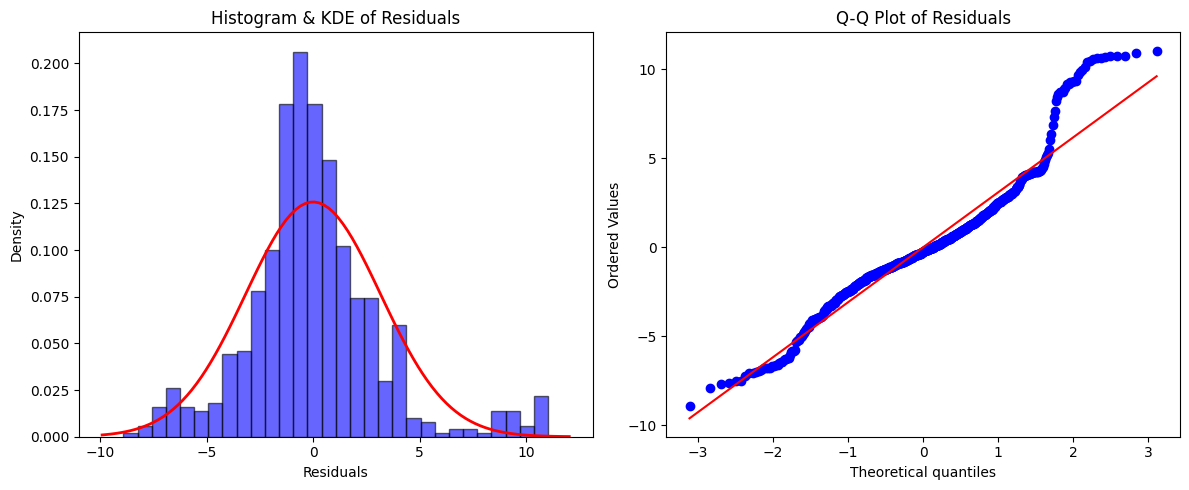

Shapiro-Wilk Test Statistic: 0.9383
Shapiro-Wilk P-value: 4.2924e-17
Conclusion: Reject the null hypothesis. Residuals are NOT normally distributed.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

# 1. Load the dataset
df = pd.read_csv('DataTrain_CoolingLoad.csv')

# 2. Fit the Ordinary Least Squares (OLS) regression model
# Predicting Cooling Load (Y) using the features (e.g., X1 to X8)
# If you used reduced features from Q1, you can adjust the formula accordingly.
formula = 'Y ~ X1 + X2 + X3 + X4 + X5 + X6 + X7 + X8'
model = ols(formula, data=df).fit()

# 3. Extract residuals
residuals = model.resid

# ==========================================
# 2(a) Plot Histogram/KDE and Q-Q Plot
# ==========================================
plt.figure(figsize=(12, 5))

# Plot 1: Histogram & KDE of Residuals
plt.subplot(1, 2, 1)
sns_plot = sns.histplot(residuals, kde=True, color='blue', bins=30) if 'sns' in globals() else None
if sns_plot is None:
    plt.hist(residuals, bins=30, density=True, alpha=0.6, color='b', edgecolor='black')
    xmin, xmax = plt.xlim()
    x = np.linspace(xmin, xmax, 100)
    p = stats.norm.pdf(x, np.mean(residuals), np.std(residuals))
    plt.plot(x, p, 'r-', linewidth=2)
plt.title('Histogram & KDE of Residuals')
plt.xlabel('Residuals')
plt.ylabel('Density')

# Plot 2: Q-Q Plot
plt.subplot(1, 2, 2)
stats.probplot(residuals, dist="norm", plot=plt)
plt.title('Q-Q Plot of Residuals')

plt.tight_layout()
plt.show()

# ==========================================
# 2(b) Formal Test of Normality (Shapiro-Wilk)
# ==========================================
shapiro_stat, shapiro_p_value = stats.shapiro(residuals)

print(f"Shapiro-Wilk Test Statistic: {shapiro_stat:.4f}")
print(f"Shapiro-Wilk P-value: {shapiro_p_value:.4e}")

# ==========================================
# 2(c) Interpretation Guide
# ==========================================
alpha = 0.05
if shapiro_p_value > alpha:
    print("Conclusion: Fail to reject the null hypothesis. Residuals are normally distributed.")
else:
    print("Conclusion: Reject the null hypothesis. Residuals are NOT normally distributed.")

PART B: MODEL DEVELOPMENT


--- First 5 Rows of the Dataset ---


,X1,X2,X3,X4,X5,X6,X7,X8,Y
0,0.98,514.5,294.0,110.25,7.0,2.0,0.0,0,21.33
1,0.98,514.5,294.0,110.25,7.0,3.0,0.0,0,21.33
2,0.98,514.5,294.0,110.25,7.0,4.0,0.0,0,21.33
3,0.98,514.5,294.0,110.25,7.0,5.0,0.0,0,21.33
4,0.90,563.5,318.5,122.50,7.0,2.0,0.0,0,28.28



--- Check for Missing Values ---
X1    1
X2    5
X3    6
X4    3
X5    0
X6    1
X7    1
X8    0
Y     0
dtype: int64

--- Summary Statistics ---


,X1,X2,X3,X4,X5,X6,X7,X8,Y
count,768.000000,768.000000,768.000000,768.000000,768.00000,768.000000,768.000000,768.00000,768.000000
mean,0.764141,671.708333,318.244792,176.827474,5.25000,3.497396,0.234180,2.81250,24.587760
std,0.105781,87.837000,43.211171,45.166119,1.75114,1.117594,0.133087,1.55096,9.513306
min,0.620000,514.500000,245.000000,110.250000,3.50000,2.000000,0.000000,0.00000,10.900000
25%,0.682500,606.375000,294.000000,147.000000,3.50000,2.750000,0.100000,1.75000,15.620000
50%,0.740000,686.000000,318.500000,220.500000,5.25000,3.000000,0.250000,3.00000,22.080000
75%,0.830000,735.000000,343.000000,220.500000,7.00000,4.000000,0.400000,4.00000,33.132500
max,0.980000,808.500000,416.500000,220.500000,7.00000,5.000000,0.400000,5.00000,48.030000


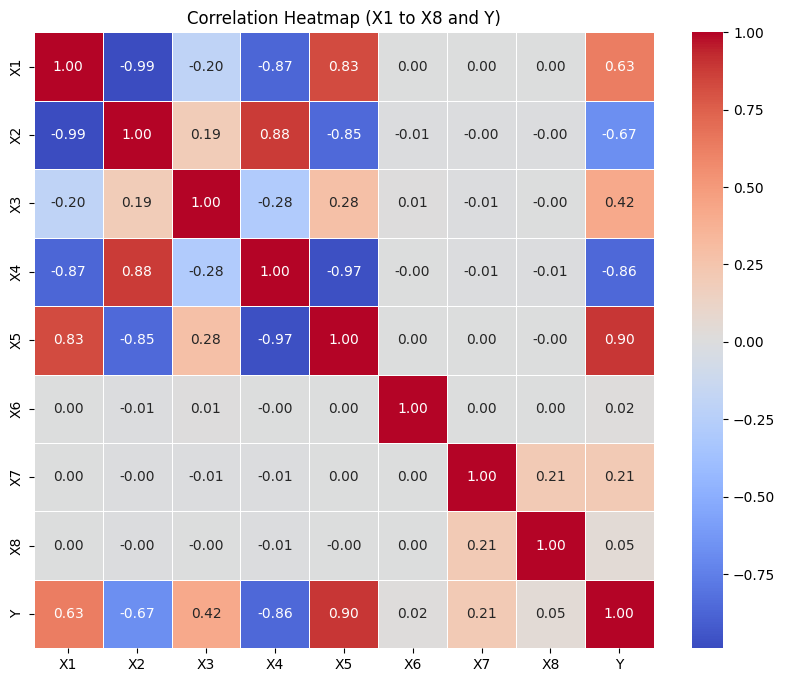

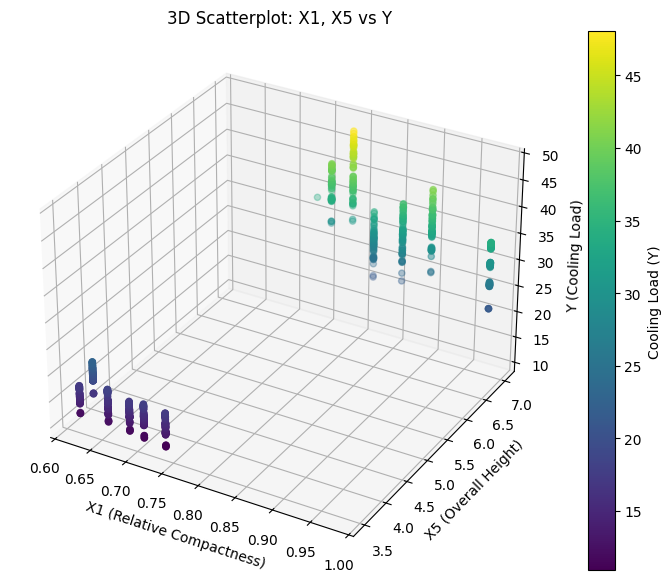


Training Set Shape (X_train): (614, 8)
Test Set Shape (X_test): (154, 8)


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from mpl_toolkits.mplot3d import Axes3D

# 1. Load the dataset
df = pd.read_csv('DataTrain_CoolingLoad.csv')

# Display the first 5 rows of the dataset
print("--- First 5 Rows of the Dataset ---")
display(df.head())

# a) Missing Value Handling & Summary Statistics
print("\n--- Check for Missing Values ---")
print(df.isnull().sum())

# If there are missing values, fill them with the median
df = df.fillna(df.median())

print("\n--- Summary Statistics ---")
display(df.describe())

# Correlation Heatmap analysis between features X1 to X8 and Y
plt.figure(figsize=(10, 8))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap (X1 to X8 and Y)')
plt.show()

# 3D Scatterplot (Example: X1, X5, and Y)
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(df['X1'], df['X5'], df['Y'], c=df['Y'], cmap='viridis', marker='o')
ax.set_xlabel('X1 (Relative Compactness)')
ax.set_ylabel('X5 (Overall Height)')
ax.set_zlabel('Y (Cooling Load)')
plt.title('3D Scatterplot: X1, X5 vs Y')
plt.colorbar(sc, label='Cooling Load (Y)')
plt.show()

# b) Split the dataset into an 80% training set and a 20% test set using random_state=42[cite: 4]
X = df[['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8']]
y = df['Y']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"\nTraining Set Shape (X_train): {X_train.shape}")
print(f"Test Set Shape (X_test): {X_test.shape}")

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# a) Fit a Multiple Linear Regression model using all features (X1 to X8)[cite: 5]
mlr = LinearRegression()
mlr.fit(X_train, y_train)

# Dapatkan intercept dan coefficients untuk persamaan regresi
intercept = mlr.intercept_
coefficients = mlr.coef_

print("--- 2(a) Fitted Regression Equation ---")
equation = f"Y = {intercept:.4f}"
for i, col in enumerate(X_train.columns):
    coef = coefficients[i]
    sign = " + " if coef >= 0 else " - "
    equation += f"{sign}{abs(coef):.4f} * {col}"

print(equation)
print("\n")

# b) Evaluasi prestasi model pada training dan testing datasets[cite: 5]
def evaluate_model(model, X_tr, y_tr, X_te, y_te):
    # Ramalan
    y_tr_pred = model.predict(X_tr)
    y_te_pred = model.predict(X_te)

    # Metrik Training
    r2_tr = model.score(X_tr, y_tr)
    n_tr, p_tr = X_tr.shape
    adj_r2_tr = 1 - ((1 - r2_tr) * (n_tr - 1) / (n_tr - p_tr - 1))
    mae_tr = mean_absolute_error(y_tr, y_tr_pred)
    rmse_tr = np.sqrt(mean_squared_error(y_tr, y_tr_pred))

    # Metrik Testing
    r2_te = model.score(X_te, y_te)
    n_te, p_te = X_te.shape
    adj_r2_te = 1 - ((1 - r2_te) * (n_te - 1) / (n_te - p_te - 1))
    mae_te = mean_absolute_error(y_te, y_te_pred)
    rmse_te = np.sqrt(mean_squared_error(y_te, y_te_pred))

    # Papar keputusan dalam bentuk jadual ringkas
    performance_df = pd.DataFrame({
        'Metric': ['R2', 'Adjusted R2', 'MAE', 'RMSE'],
        'Training Set': [r2_tr, adj_r2_tr, mae_tr, rmse_tr],
        'Testing Set': [r2_te, adj_r2_te, mae_te, rmse_te]
    })
    return performance_df

print("--- 2(b) Model Performance Evaluation ---")
perf_results = evaluate_model(mlr, X_train, y_train, X_test, y_test)
print(perf_results.to_string(index=False))

--- 2(a) Fitted Regression Equation ---
Y = 91.4557 - 66.2149 * X1 - 0.0260 * X2 - 0.0121 * X3 - 0.1171 * X4 + 4.1867 * X5 + 0.0378 * X6 + 14.7965 * X7 + 0.0292 * X8


--- 2(b) Model Performance Evaluation ---
     Metric  Training Set  Testing Set
         R2      0.885904     0.886370
Adjusted R2      0.884395     0.880101
        MAE      2.259629     2.242660
       RMSE      3.198400     3.244786


In [7]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_poly_model(degree, X_tr, y_tr, X_te, y_te):
    # 1. Transformasi ciri kepada darjah polinomial (termasuk terma interaksi)
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_tr_poly = poly.fit_transform(X_tr)
    X_te_poly = poly.transform(X_te)

    # 2. Latih model Linear Regression menggunakan ciri polinomial
    model = LinearRegression()
    model.fit(X_tr_poly, y_tr)

    # 3. Membuat ramalan
    y_tr_pred = model.predict(X_tr_poly)
    y_te_pred = model.predict(X_te_poly)

    # 4. Pengiraan Metrik (R2, Adjusted R2, MAE, RMSE) untuk Training
    r2_tr = model.score(X_tr_poly, y_tr)
    n_tr, p_tr = X_tr_poly.shape
    adj_r2_tr = 1 - ((1 - r2_tr) * (n_tr - 1) / (n_tr - p_tr - 1))
    mae_tr = mean_absolute_error(y_tr, y_tr_pred)
    rmse_tr = np.sqrt(mean_squared_error(y_tr, y_tr_pred))

    # Pengiraan Metrik untuk Testing
    r2_te = model.score(X_te_poly, y_te)
    n_te, p_te = X_te_poly.shape
    adj_r2_te = 1 - ((1 - r2_te) * (n_te - 1) / (n_te - p_te - 1))
    mae_te = mean_absolute_error(y_te, y_te_pred)
    rmse_te = np.sqrt(mean_squared_error(y_te, y_te_pred))

    return [r2_tr, adj_r2_tr, mae_tr, rmse_tr], [r2_te, adj_r2_te, mae_te, rmse_te]

# Jalankan untuk Degree 2 dan Degree 3
metrics = ['R2', 'Adjusted R2', 'MAE', 'RMSE']

tr_deg2, te_deg2 = evaluate_poly_model(2, X_train, y_train, X_test, y_test)
tr_deg3, te_deg3 = evaluate_poly_model(3, X_train, y_train, X_test, y_test)

# Paparkan jadual perbandingan prestasi
comparison_df = pd.DataFrame({
    'Metric': metrics,
    'Degree 2 (Train)': tr_deg2,
    'Degree 2 (Test)': te_deg2,
    'Degree 3 (Train)': tr_deg3,
    'Degree 3 (Test)': te_deg3
})

print("--- Perbandingan Prestasi Polynomial Regression (Degree 2 vs Degree 3) ---")
print(comparison_df.to_string(index=False))

--- Perbandingan Prestasi Polynomial Regression (Degree 2 vs Degree 3) ---
     Metric  Degree 2 (Train)  Degree 2 (Test)  Degree 3 (Train)  Degree 3 (Test)
         R2          0.973244    -55511.772538          0.978849     -1284.239695
Adjusted R2          0.971175    -77920.598149          0.971123     17877.515752
        MAE          1.035263       262.465988          0.974705        41.235814
       RMSE          1.548839      2267.963870          1.377099       345.089494


In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

# 4a) Standardise the numerical predictors (X1 through X8) using Z-score scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4b) Perform Principal Component Analysis (PCA) on the scaled feature set
# Mengambil komponen yang merangkumi 95% varians (atau anda boleh tetapkan n_components tertentu)
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Bilangan Principal Components yang dipilih: {X_train_pca.shape[1]}")

# 4c) Examine the eigenvector loadings for PC1 and PC2
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i+1}' for i in range(pca.n_components_)],
    index=X_train.columns
)
print("\n--- Eigenvector Loadings untuk PC1 dan PC2 ---")
print(loadings[['PC1', 'PC2']])

# 4d) Train an MLR + PCA model using the selected components to predict Cooling Load (Y)
mlr_pca = LinearRegression()
mlr_pca.fit(X_train_pca, y_train)

# 4e) Evaluate model performance on the test set
y_pred_pca = mlr_pca.predict(X_test_pca)
r2_pca = mlr_pca.score(X_test_pca, y_test)
n_te, p_te = X_test_pca.shape
adj_r2_pca = 1 - ((1 - r2_pca) * (n_te - 1) / (n_te - p_te - 1))
mae_pca = mean_absolute_error(y_test, y_pred_pca)
rmse_pca = np.sqrt(mean_squared_error(y_test, y_pred_pca))

print("\n--- Prestasi MLR + PCA Model (Test Set) ---")
print(f"R2          : {r2_pca:.4f}")
print(f"Adjusted R2 : {adj_r2_pca:.4f}")
print(f"MAE         : {mae_pca:.4f}")
print(f"RMSE        : {rmse_pca:.4f}")

Bilangan Principal Components yang dipilih: 5

--- Eigenvector Loadings untuk PC1 dan PC2 ---
         PC1       PC2
X1 -0.496960 -0.197778
X2  0.501720  0.190730
X3 -0.024467  0.755197
X4  0.504536 -0.176809
X5 -0.496085  0.179438
X6 -0.001015 -0.009335
X7 -0.007110 -0.385505
X8  0.000084 -0.376860

--- Prestasi MLR + PCA Model (Test Set) ---
R2          : 0.8267
Adjusted R2 : 0.8209
MAE         : 2.8294
RMSE        : 4.0071


PART C: MODEL DEPLOYMENT

In [18]:
import streamlit as st
import numpy as np
import pandas as pd
import joblib
import os

# ==========================================
# 1. KONFIGURASI HALAMAN STREAMLIT
# ==========================================
st.set_page_config(
    page_title="Building Energy Efficiency Predictor",
    page_icon="🏢",
    layout="wide"
)

# ==========================================
# 2. TAJUK & PENERANGAN APLIKASI
# ==========================================
st.title("🏢 Building Energy Efficiency & Cooling Load Predictor")
st.markdown("""
Aplikasi web interaktif ini menggunakan model **Degree 2 Polynomial Regression** yang telah dilatih untuk meramal
beban penyejukan bangunan (**Cooling Load - $Y$**) berdasarkan ciri-ciri geometri dan seni bina bangunan.
Laraskan parameter pada panel sisi (*sidebar*) di sebelah kiri untuk melihat simulasi ramalan.
""")
st.markdown("---")

# ==========================================
# 3. PANEL SISI: INPUT PARAMETER FIZIKAL
# ==========================================
st.sidebar.header("🎛️ Parameter Seni Bina Bangunan")
st.sidebar.markdown("Sila laraskan nilai pembolehubah fizikal bangunan:")

def user_input_features():
    relative_compactness = st.sidebar.slider("Relative Compactness ($X_1$)", 0.60, 1.00, 0.75, 0.01)
    surface_area = st.sidebar.slider("Surface Area ($X_2$) [$m^2$]", 500.0, 850.0, 670.0, 5.0)
    wall_area = st.sidebar.slider("Wall Area ($X_3$) [$m^2$]", 245.0, 420.0, 318.0, 2.0)
    roof_area = st.sidebar.slider("Roof Area ($X_4$) [$m^2$]", 110.0, 220.0, 147.5, 1.0)
    overall_height = st.sidebar.selectbox("Overall Height ($X_5$) [m]", [3.5, 7.0])
    orientation = st.sidebar.selectbox("Orientation ($X_6$)", [2, 3, 4, 5], format_func=lambda x: f"Arah / Arah {x}")
    glazing_area = st.sidebar.slider("Glazing Area ($X_7$)", 0.0, 0.4, 0.2, 0.05)
    glazing_distribution = st.sidebar.selectbox("Glazing Area Distribution ($X_8$)", [0, 1, 2, 3, 4, 5])

    data = {
        'X1': relative_compactness,
        'X2': surface_area,
        'X3': wall_area,
        'X4': roof_area,
        'X5': overall_height,
        'X6': orientation,
        'X7': glazing_area,
        'X8': glazing_distribution
    }
    return pd.DataFrame(data, index=[0])

# Dapatkan data input daripada pengguna
input_df = user_input_features()

# ==========================================
# 4. PAPARAN RINGKASAN INPUT SEMASA
# ==========================================
st.subheader("📋 Konfigurasi Reka Bentuk Semasa")
st.dataframe(input_df, use_container_width=True)

# ==========================================
# 5. LOAD MODEL & TRANSFORMER (.JOBLIB)
# ==========================================
@st.cache_resource
def load_trained_assets():
    transformer_path = 'polynomial_transformer_deg2.joblib'
    model_path = 'best_poly_model.joblib'

    if os.path.exists(transformer_path) and os.path.exists(model_path):
        poly = joblib.load(transformer_path)
        model = joblib.load(model_path)
        return poly, model, True
    return None, None, False

poly_transformer, poly_model, assets_loaded = load_trained_assets()

# ==========================================
# 6. PROSES RAMALAN (PREDICTION) & PAPARAN
# ==========================================
st.markdown("---")
st.subheader("⚡ Hasil Ramalan Beban Penyejukan (Cooling Load)")

if assets_loaded:
    # Susunan kolum mesti sama seperti semasa proses training model
    features_to_use = ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8']
    model_input = input_df[features_to_use]

    # Transform input kepada ciri Polynomial Degree 2
    input_poly = poly_transformer.transform(model_input)

    # Jalankan ramalan menggunakan model terlatih
    prediction = poly_model.predict(input_poly)[0]

    # Paparan Metrik Keputusan dalam bentuk Kolum
    col1, col2 = st.columns(2)

    with col1:
        st.metric(
            label="Anggaran Beban Penyejukan ($Y$)",
            value=f"{prediction:.2f} kWh",
            delta="Kecekapan Optimum" if prediction < 25 else "Permintaan Tenaga Tinggi",
            delta_color="inverse"
        )

    with col2:
        st.info("""
        **Analisis & Implikasi Kejuruteraan:**
        * **Interaksi Bukan Linear:** Model polynomial berjaya mengambil kira kesan pendaraban antara ketinggian dan luas permukaan bangunan.
        * **Pengurusan Tenaga:** Perubahan pada nilai kekompakan (*compactness*) dan taburan cermin (*glazing*) mengubah profil tenaga bangunan secara langsung.
        """)
else:
    st.error("""
    ⚠️ **Ralat: Fail Model Tidak Dijumpai!**
    Sila pastikan fail berikut berada di dalam folder yang sama dengan fail `app.py`:
    1. `polynomial_transformer_deg2.joblib`
    2. `best_poly_model.joblib`
    """)

# ==========================================
# 7. FOOTER / BAHAGIAN BAWAH
# ==========================================
st.markdown("---")
st.caption("Dibangunkan untuk Tugasan Analisis Ramalan & Pengoptimuman Tenaga Bangunan | Dikuasakan oleh Streamlit")

2026-11-08 13:59:11.095 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-08 13:59:11.098 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-08 13:59:11.102 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-08 13:59:11.103 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-08 13:59:11.106 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-08 13:59:11.110 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-08 13:59:11.111 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-08 13:59:11.113 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

DeltaGenerator()

In [19]:
pip install streamlit pandas numpy scikit-learn joblib

In [20]:
import streamlit as st
import numpy as np
import pandas as pd
import joblib
import os

# Konfigurasi Halaman Streamlit
st.set_page_config(
    page_title="Building Energy Efficiency Predictor",
    page_icon="🏢",
    layout="wide"
)

# Tajuk & Penerangan Aplikasi
st.title("🏢 Building Energy Efficiency & Cooling Load Predictor")
st.markdown("""
Aplikasi web interaktif ini menggunakan model **Degree 2 Polynomial Regression** yang telah dilatih untuk meramal
beban penyejukan bangunan (**Cooling Load - $Y$**) berdasarkan ciri-ciri geometri dan seni bina bangunan.
""")
st.markdown("---")

# Panel Sisi: Input Parameter Fizikal
st.sidebar.header("🎛️ Parameter Seni Bina Bangunan")

def user_input_features():
    relative_compactness = st.sidebar.slider("Relative Compactness ($X_1$)", 0.60, 1.00, 0.75, 0.01)
    surface_area = st.sidebar.slider("Surface Area ($X_2$) [$m^2$]", 500.0, 850.0, 670.0, 5.0)
    wall_area = st.sidebar.slider("Wall Area ($X_3$) [$m^2$]", 245.0, 420.0, 318.0, 2.0)
    roof_area = st.sidebar.slider("Roof Area ($X_4$) [$m^2$]", 110.0, 220.0, 147.5, 1.0)
    overall_height = st.sidebar.selectbox("Overall Height ($X_5$) [m]", [3.5, 7.0])
    orientation = st.sidebar.selectbox("Orientation ($X_6$)", [2, 3, 4, 5], format_func=lambda x: f"Arah {x}")
    glazing_area = st.sidebar.slider("Glazing Area ($X_7$)", 0.0, 0.4, 0.2, 0.05)
    glazing_distribution = st.sidebar.selectbox("Glazing Area Distribution ($X_8$)", [0, 1, 2, 3, 4, 5])

    data = {
        'X1': relative_compactness,
        'X2': surface_area,
        'X3': wall_area,
        'X4': roof_area,
        'X5': overall_height,
        'X6': orientation,
        'X7': glazing_area,
        'X8': glazing_distribution
    }
    return pd.DataFrame(data, index=[0])

input_df = user_input_features()

# Paparan Ringkasan Input Semasa
st.subheader("📋 Konfigurasi Reka Bentuk Semasa")
st.dataframe(input_df, use_container_width=True)

# Load Model & Transformer (.joblib)
@st.cache_resource
def load_trained_assets():
    transformer_path = 'polynomial_transformer_deg2.joblib'
    model_path = 'best_poly_model.joblib'

    if os.path.exists(transformer_path) and os.path.exists(model_path):
        poly = joblib.load(transformer_path)
        model = joblib.load(model_path)
        return poly, model, True
    return None, None, False

poly_transformer, poly_model, assets_loaded = load_trained_assets()

# Proses Ramalan & Paparan Hasil
st.markdown("---")
st.subheader("⚡ Hasil Ramalan Beban Penyejukan (Cooling Load)")

if assets_loaded:
    features_to_use = ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8']
    model_input = input_df[features_to_use]

    # Transform input kepada ciri Polynomial Degree 2
    input_poly = poly_transformer.transform(model_input)

    # Jalankan ramalan
    prediction = poly_model.predict(input_poly)[0]

    col1, col2 = st.columns(2)

    with col1:
        st.metric(
            label="Anggaran Beban Penyejukan ($Y$)",
            value=f"{prediction:.2f} kWh",
            delta="Kecekapan Optimum" if prediction < 25 else "Permintaan Tenaga Tinggi",
            delta_color="inverse"
        )

    with col2:
        st.info("""
        **Analisis Kejuruteraan:**
        * **Interaksi Bukan Linear:** Model polynomial berjaya menilai kesan gabungan ruang dan ketinggian struktur terhadap haba.
        * **Pengoptimuman Reka Bentuk:** Pelarasan pada parameter kekompakan dan taburan cermin membantu jurutera merancang kapasiti HVAC yang lebih cekap.
        """)
else:
    st.error("⚠️ Sila pastikan fail `polynomial_transformer_deg2.joblib` dan `best_poly_model.joblib` dimuat naik ke dalam direktori aplikasi.")

2026-11-08 14:02:00.420 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-08 14:02:00.426 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-08 14:02:00.430 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-08 14:02:00.432 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-08 14:02:00.437 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-08 14:02:00.439 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-08 14:02:00.443 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-08 14:02:00.449 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar